# Tasks 3–4 — Pandas
Цены объявлений в тенге, не сделок.

[Источник: raimbekovm](https://huggingface.co/datasets/raimbekovm/astana-real-estate), CC BY 4.0; 08.10.2026.

### 3.1. Загрузка и обзор

In [1]:
# Импорт нужен для самостоятельного запуска этого файла
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 35)
pd.set_option("display.max_rows", 40)
pd.set_option("display.max_colwidth", 45)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
source_path = Path("listings.csv")
assert source_path.is_file(), "Положите listings.csv рядом с Notebook."
raw = pd.read_csv(source_path)
display(raw.head(5), raw.tail(5))
print("Форма:", raw.shape)
print("Колонки:", raw.columns.tolist())
display(raw.dtypes.rename("dtype").to_frame())
raw.info()
display(raw.describe(include="all"))
display(Markdown(f"**{raw.shape[0]:,} объявлений, {raw.shape[1]} колонок.** "
                 "Цены, размеры, здания, адреса и даты. "
                 "CSV один."))

,listing_id,url,city,price_kzt,price_usd,price_per_m2_usd,rooms,total_area_m2,kitchen_area_m2,floor,total_floors,ceiling_height,building_type,year_built,condition,bathroom,balcony,parking,furniture,flooring,security,residential_complex_name,address,district,latitude,longitude,parsed_at
0,691048362,https://krisha.kz/a/show/691048362?srchid...,astana,38497500,75646,1043,2,72.50,NaN,NaN,NaN,NaN,монолитный,2023,NaN,совмещенный,NaN,NaN,NaN,NaN,NaN,Respublika,Е-36 5,Нура р-н,51.13,71.39,2026-01-03T20:50:46.421397
1,1004599137,https://krisha.kz/a/show/1004599137?srchi...,astana,45000000,88424,990,3,89.30,11.80,4.00,5.00,2.80,кирпичный,2014,NaN,2 с/у и более,балкон и лоджия,паркинг,полностью,ламинат,NaN,Family Town,Е652 6,Есильский р-н,51.06,71.42,2026-01-03T20:50:52.735945
2,761512600,https://krisha.kz/a/show/761512600?srchid...,astana,29000000,56984,790,2,72.10,NaN,NaN,NaN,2.70,монолитный,1998,"не новый, но аккуратный ремонт",2 с/у и более,лоджия,NaN,полностью,ламинат,"видеонаблюдение, видеодомофон, консьерж",Свечки,Богенбай батыра 30,Сарыарка р-н,51.19,71.36,2026-01-03T20:51:01.431439
3,1007029481,https://krisha.kz/a/show/1007029481?srchi...,astana,76000000,149338,1398,4,106.77,11.13,8.00,9.00,3.00,монолитный,2023,NaN,NaN,NaN,паркинг,NaN,NaN,NaN,Sezim Qala.Baqyt,Туран 55/12,Нура р-н,51.11,71.39,2026-01-03T20:51:09.278359
4,697845378,https://krisha.kz/a/show/697845378?srchid...,astana,14000000,27509,705,2,39.00,NaN,2.00,2.00,2.70,кирпичный,2021,NaN,совмещенный,лоджия,паркинг,NaN,ламинат,"охрана, домофон, кодовый замок",Boston Comfort House,"мкр Уркер, Кургальжинское шоссе 108",Нура р-н,51.12,71.28,2026-01-03T20:51:19.144336


,listing_id,url,city,price_kzt,price_usd,price_per_m2_usd,rooms,total_area_m2,kitchen_area_m2,floor,total_floors,ceiling_height,building_type,year_built,condition,bathroom,balcony,parking,furniture,flooring,security,residential_complex_name,address,district,latitude,longitude,parsed_at
18383,1006690128,https://krisha.kz/a/show/1006690128?srchi...,astana,47000000,92354,1412,2,65.40,10.60,7.00,12.00,3.00,монолитный,2025,свежий ремонт,2 с/у и более,балкон и лоджия,паркинг,полностью,ламинат,"охрана, домофон, кодовый замок, видеонабл...",Яссауи,Кабанбай батыр 63,Нура р-н,51.07,71.40,2026-01-06T00:15:50.724620
18384,699828528,https://krisha.kz/a/show/699828528?srchid...,astana,31000000,60914,1561,2,39.00,NaN,2.00,12.00,2.70,кирпичный,2024,свежий ремонт,совмещенный,балкон,паркинг,полностью,ламинат,NaN,Гималаи,Нажмиденова 15,Алматы р-н,51.11,71.51,2026-01-06T00:15:59.138597
18385,1008250460,https://krisha.kz/a/show/1008250460?srchi...,astana,37000000,72704,1041,2,69.80,9.20,2.00,9.00,2.50,кирпичный,2020,свежий ремонт,раздельный,лоджия,рядом охраняемая стоянка,полностью,ламинат,"домофон, видеонаблюдение, видеодомофон",NaN,омарова 23/1,Нура р-н,51.14,71.37,2026-01-06T00:16:02.112484
18386,1008289184,https://krisha.kz/a/show/1008289184,astana,30500000,59932,799,3,75.00,NaN,7.00,9.00,NaN,панельный,2008,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Момышулы 4,Алматы р-н,51.14,71.47,2026-01-06T00:16:05.207213
18387,1008065913,https://krisha.kz/a/show/1008065913,astana,37000000,72704,1773,2,41.00,18.00,7.00,12.00,NaN,кирпичный,2021,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Керей жанибек 44/2,Есильский р-н,51.11,71.45,2026-01-06T00:16:08.635132


Форма: (18388, 27)
Колонки: ['listing_id', 'url', 'city', 'price_kzt', 'price_usd', 'price_per_m2_usd', 'rooms', 'total_area_m2', 'kitchen_area_m2', 'floor', 'total_floors', 'ceiling_height', 'building_type', 'year_built', 'condition', 'bathroom', 'balcony', 'parking', 'furniture', 'flooring', 'security', 'residential_complex_name', 'address', 'district', 'latitude', 'longitude', 'parsed_at']


,dtype
listing_id,int64
url,object
city,object
price_kzt,int64
price_usd,int64
price_per_m2_usd,int64
rooms,int64
total_area_m2,float64
kitchen_area_m2,float64
floor,float64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18388 entries, 0 to 18387
Data columns (total 27 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   listing_id                18388 non-null  int64  
 1   url                       18388 non-null  object 
 2   city                      18388 non-null  object 
 3   price_kzt                 18388 non-null  int64  
 4   price_usd                 18388 non-null  int64  
 5   price_per_m2_usd          18388 non-null  int64  
 6   rooms                     18388 non-null  int64  
 7   total_area_m2             18388 non-null  float64
 8   kitchen_area_m2           7621 non-null   float64
 9   floor                     17417 non-null  float64
 10  total_floors              17417 non-null  float64
 11  ceiling_height            15189 non-null  float64
 12  building_type             17271 non-null  object 
 13  year_built                18388 non-null  int64  
 14  condit

,listing_id,url,city,price_kzt,price_usd,price_per_m2_usd,rooms,total_area_m2,kitchen_area_m2,floor,total_floors,ceiling_height,building_type,year_built,condition,bathroom,balcony,parking,furniture,flooring,security,residential_complex_name,address,district,latitude,longitude,parsed_at
count,"18,388.00",18388,18388,"18,388.00","18,388.00","18,388.00","18,388.00","18,388.00","7,621.00","17,417.00","17,417.00","15,189.00",17271,"18,388.00",7501,11224,9407,12651,9065,7887,8245,14495,18388,17610,"18,388.00","18,388.00",18388
unique,NaN,18388,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN,5,4,4,3,3,7,176,1185,10280,6,NaN,NaN,18388
top,NaN,https://krisha.kz/a/show/691048362?srchid...,astana,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,монолитный,NaN,свежий ремонт,совмещенный,лоджия,паркинг,полностью,ламинат,"домофон, видеонаблюдение",Respublika,М. Тынышбайулы 5,Есильский р-н,NaN,NaN,2026-01-03T20:50:46.421397
freq,NaN,1,18388,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9515,NaN,3866,5746,4369,11608,6171,6475,1925,164,53,5121,NaN,NaN,1
mean,"972,504,079.30",NaN,NaN,"47,813,121.93","93,951.54","1,240.03",2.32,73.05,13.12,6.77,11.56,2.90,NaN,"2,016.71",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51.12,71.43,NaN
std,"100,572,703.19",NaN,NaN,"41,127,492.40","80,814.85",418.12,1.04,41.69,10.68,4.33,5.11,0.61,NaN,11.19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.20,0.33,NaN
min,"19,402,543.00",NaN,NaN,"3,990,000.00","7,840.00",98.00,1.00,10.80,1.20,1.00,2.00,2.00,NaN,"1,950.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42.35,51.91,NaN
25%,"1,005,556,171.00",NaN,NaN,"25,500,000.00","50,107.00",944.00,2.00,43.70,10.00,3.00,9.00,2.70,NaN,"2,013.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51.11,71.39,NaN
50%,"1,007,650,326.00",NaN,NaN,"36,000,000.00","70,739.00","1,161.00",2.00,63.00,12.00,6.00,10.00,3.00,NaN,"2,020.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51.13,71.43,NaN
75%,"1,008,192,162.00",NaN,NaN,"55,000,000.00","108,074.00","1,448.00",3.00,90.00,15.00,9.00,14.00,3.00,NaN,"2,024.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51.15,71.47,NaN


**18,388 объявлений, 27 колонок.** Цены, размеры, здания, адреса и даты. CSV один.

### 3.2. Дубликаты

In [2]:
# Проверяем полные повторы и ID
full_duplicate_count = raw.duplicated().sum()
key_duplicate_count = raw.duplicated(subset=["listing_id"]).sum()
print("Полных дубликатов:", full_duplicate_count)
print("Повторных ID:", key_duplicate_count)
display(raw.loc[raw.duplicated(keep=False)].head())
display(raw.loc[raw.duplicated("listing_id", keep=False),
                ["listing_id", "price_kzt", "address", "parsed_at"]].head())
df = raw.copy()
print("Строк до / после проверки дубликатов:", len(raw), len(df))
assert full_duplicate_count == 0 and key_duplicate_count == 0

Полных дубликатов: 0
Повторных ID: 0


,listing_id,url,city,price_kzt,price_usd,price_per_m2_usd,rooms,total_area_m2,kitchen_area_m2,floor,total_floors,ceiling_height,building_type,year_built,condition,bathroom,balcony,parking,furniture,flooring,security,residential_complex_name,address,district,latitude,longitude,parsed_at


,listing_id,price_kzt,address,parsed_at


Строк до / после проверки дубликатов: 18388 18388


### 3.3. Пропуски

In [3]:
# Считаем количество и процент пропусков, чтобы выбрать способ очистки
missing_before = pd.DataFrame({"missing_count": df.isna().sum(),
                               "missing_percent": df.isna().mean() * 100})
display(missing_before.sort_values("missing_count", ascending=False))
display(df[["kitchen_area_m2", "ceiling_height", "floor", "total_floors"]].describe())
print("Кухня больше общей площади:", (df.kitchen_area_m2 > df.total_area_m2).sum())
print("Потолок вне 2–6 м:", ((df.ceiling_height < 2) | (df.ceiling_height > 6)).sum())

,missing_count,missing_percent
condition,10887,59.21
kitchen_area_m2,10767,58.55
flooring,10501,57.11
security,10143,55.16
furniture,9323,50.70
balcony,8981,48.84
bathroom,7164,38.96
parking,5737,31.20
residential_complex_name,3893,21.17
ceiling_height,3199,17.40


,kitchen_area_m2,ceiling_height,floor,total_floors
count,"7,621.00","15,189.00","17,417.00","17,417.00"
mean,13.12,2.90,6.77,11.56
std,10.68,0.61,4.33,5.11
min,1.20,2.00,1.00,2.00
25%,10.00,2.70,3.00,9.00
50%,12.00,3.00,6.00,10.00
75%,15.00,3.00,9.00,14.00
max,707.00,28.00,41.00,43.00


Кухня больше общей площади: 13
Потолок вне 2–6 м: 9


In [4]:
# Отмечаем замены флагом
df["ceiling_imputed"] = (df.ceiling_height.isna()
                         | ~df.ceiling_height.between(2, 6))
df.loc[df["ceiling_imputed"], "ceiling_height"] = np.nan
ceiling_group_median = df.groupby("building_type")["ceiling_height"].transform("median")
df["ceiling_height"] = df.ceiling_height.fillna(ceiling_group_median).fillna(df.ceiling_height.median())
df = df.drop(columns="kitchen_area_m2")
categorical_columns = ["building_type", "condition", "bathroom", "balcony", "parking",
                       "furniture", "flooring", "security", "residential_complex_name", "district"]
df[categorical_columns] = df[categorical_columns].fillna("Unknown")
missing_after = pd.DataFrame({"missing_count": df.isna().sum(),
                              "missing_percent": df.isna().mean() * 100})
display(missing_after.sort_values("missing_count", ascending=False))
print("Заменено высот потолка:", df.ceiling_imputed.sum())

,missing_count,missing_percent
floor,971,5.28
total_floors,971,5.28
listing_id,0,0.00
balcony,0,0.00
parsed_at,0,0.00
longitude,0,0.00
latitude,0,0.00
district,0,0.00
address,0,0.00
residential_complex_name,0,0.00


Заменено высот потолка: 3208


### 3.4. Преобразование типов

In [5]:
# Приводим числа и дату к нужным типам
numeric_columns = ["listing_id", "price_kzt", "price_usd", "price_per_m2_usd", "rooms",
                   "total_area_m2", "floor", "total_floors", "ceiling_height",
                   "year_built", "latitude", "longitude"]
numeric_objects = df[numeric_columns].select_dtypes(include=["object", "string"]).columns.tolist()
print("Числовые поля с текстовым типом:", numeric_objects)
before_conversion = df[numeric_columns + ["parsed_at"]].isna().sum()
for column in numeric_columns:
    if column in numeric_objects:
        df[column] = (df[column].astype("string")
                      .str.replace(r"[\s\u00a0]", "", regex=True)
                      .str.replace(",", ".", regex=False))
    df[column] = pd.to_numeric(df[column], errors="coerce")
df["parsed_at"] = pd.to_datetime(df["parsed_at"], errors="coerce")
new_nan = df[numeric_columns + ["parsed_at"]].isna().sum() - before_conversion
display(new_nan.rename("new_missing_after_conversion").to_frame())
display(df.dtypes.rename("dtype").to_frame())
assert new_nan.eq(0).all()
print("Период сбора:", df.parsed_at.min(), "—", df.parsed_at.max())

Числовые поля с текстовым типом: []


,new_missing_after_conversion
listing_id,0
price_kzt,0
price_usd,0
price_per_m2_usd,0
rooms,0
total_area_m2,0
floor,0
total_floors,0
ceiling_height,0
year_built,0


,dtype
listing_id,int64
url,object
city,object
price_kzt,int64
price_usd,int64
price_per_m2_usd,int64
rooms,int64
total_area_m2,float64
floor,float64
total_floors,float64


Период сбора: 2026-01-03 20:50:46.421397 — 2026-01-06 00:16:08.635132


### 3.5. Переименование и новые признаки

In [6]:
# Сокращаем названия и создаём признаки для сравнения квартир
rename_map = {"listing_id": "id", "price_kzt": "price", "total_area_m2": "area",
              "residential_complex_name": "complex", "ceiling_height": "ceiling_m",
              "parsed_at": "collected_at"}
display(pd.Series(rename_map, name="new_name").rename_axis("source_name").to_frame())
df = df.rename(columns=rename_map)
valid_core = (np.isfinite(df["area"]) & (df["area"] > 0)
              & np.isfinite(df["price"]) & (df["price"] > 0))
print("Строк с некорректной площадью или ценой:", (~valid_core).sum())
df = df.loc[valid_core].copy()
df["price_per_m2"] = df["price"] / df["area"]
valid_floor = (df["floor"].notna() & df["total_floors"].notna()
               & (df["floor"] >= 1) & (df["floor"] <= df["total_floors"]))
df["floor_category"] = np.select(
    [valid_floor & df["floor"].eq(1), valid_floor & df["floor"].eq(df["total_floors"]), valid_floor],
    ["first", "last", "middle"], default="unknown")
df["area_category"] = pd.cut(df["area"], bins=[0, 50, 80, 120, np.inf],
                             labels=["small: <=50 m²", "medium: 50–80 m²",
                                     "large: 80–120 m²", "very large: >120 m²"])
ANALYSIS_YEAR = 2026
df["future_completion"] = df.year_built > ANALYSIS_YEAR
df["building_age"] = (ANALYSIS_YEAR - df.year_built).where(~df.future_completion)
print("Будущих годов постройки; возраст неизвестен:", df.future_completion.sum())
display(df[["price", "area", "price_per_m2", "floor", "total_floors", "floor_category",
            "area_category", "year_built", "building_age"]].head())
display(df.floor_category.value_counts().rename("count").to_frame())

,new_name
source_name,
listing_id,id
price_kzt,price
total_area_m2,area
residential_complex_name,complex
ceiling_height,ceiling_m
parsed_at,collected_at


Строк с некорректной площадью или ценой: 0


Будущих годов постройки; возраст неизвестен: 37


,price,area,price_per_m2,floor,total_floors,floor_category,area_category,year_built,building_age
0,38497500,72.50,"531,000.00",NaN,NaN,unknown,medium: 50–80 m²,2023,3.00
1,45000000,89.30,"503,919.37",4.00,5.00,middle,large: 80–120 m²,2014,12.00
2,29000000,72.10,"402,219.14",NaN,NaN,unknown,medium: 50–80 m²,1998,28.00
3,76000000,106.77,"711,810.43",8.00,9.00,middle,large: 80–120 m²,2023,3.00
4,14000000,39.00,"358,974.36",2.00,2.00,last,small: <=50 m²,2021,5.00


,count
floor_category,
middle,14629
last,1974
unknown,971
first,814


### 3.6. Сохранение и проверка

In [7]:
# assert останавливает выполнение при ошибке
assert df["id"].is_unique
assert df["area"].gt(0).all() and df["price"].gt(0).all()
assert np.isfinite(df["price_per_m2"]).all()
assert df.loc[~valid_floor, "floor_category"].eq("unknown").all()
df.to_csv("apartments_clean.csv", index=False)
reloaded = pd.read_csv("apartments_clean.csv", parse_dates=["collected_at"])
print("Форма очищенных данных:", df.shape, "после чтения:", reloaded.shape)
assert reloaded.shape == df.shape
assert reloaded.columns.tolist() == df.columns.tolist()
assert np.array_equal(reloaded["id"], df["id"])
assert np.allclose(reloaded["price_per_m2"], reloaded["price"] / reloaded["area"])
pd.testing.assert_frame_equal(df.astype({"area_category": "object"}), reloaded,
                              check_dtype=False, check_exact=False, rtol=1e-10, atol=1e-10)
display(reloaded.head(3))
display(df.isna().sum().loc[lambda counts: counts > 0].rename("intentional_missing").to_frame())
print("CSV проверен: без индекса, значения совпадают, цена за м² конечна.")

Форма очищенных данных: (18388, 32) после чтения: (18388, 32)


,id,url,city,price,price_usd,price_per_m2_usd,rooms,area,floor,total_floors,ceiling_m,building_type,year_built,condition,bathroom,balcony,parking,furniture,flooring,security,complex,address,district,latitude,longitude,collected_at,ceiling_imputed,price_per_m2,floor_category,area_category,future_completion,building_age
0,691048362,https://krisha.kz/a/show/691048362?srchid...,astana,38497500,75646,1043,2,72.50,NaN,NaN,3.00,монолитный,2023,Unknown,совмещенный,Unknown,Unknown,Unknown,Unknown,Unknown,Respublika,Е-36 5,Нура р-н,51.13,71.39,2026-01-03 20:50:46.421397,True,"531,000.00",unknown,medium: 50–80 m²,False,3.00
1,1004599137,https://krisha.kz/a/show/1004599137?srchi...,astana,45000000,88424,990,3,89.30,4.00,5.00,2.80,кирпичный,2014,Unknown,2 с/у и более,балкон и лоджия,паркинг,полностью,ламинат,Unknown,Family Town,Е652 6,Есильский р-н,51.06,71.42,2026-01-03 20:50:52.735945,False,"503,919.37",middle,large: 80–120 m²,False,12.00
2,761512600,https://krisha.kz/a/show/761512600?srchid...,astana,29000000,56984,790,2,72.10,NaN,NaN,2.70,монолитный,1998,"не новый, но аккуратный ремонт",2 с/у и более,лоджия,Unknown,полностью,ламинат,"видеонаблюдение, видеодомофон, консьерж",Свечки,Богенбай батыра 30,Сарыарка р-н,51.19,71.36,2026-01-03 20:51:01.431439,False,"402,219.14",unknown,medium: 50–80 m²,False,28.00


,intentional_missing
floor,971
total_floors,971
building_age,37


CSV проверен: без индекса, значения совпадают, цена за м² конечна.


### 4.1. Статистика и фильтры

In [8]:
# Используем только очищенные данные
apartments = df.copy()
display(apartments.select_dtypes(include="number").describe())
informative_columns = ["id", "district", "complex", "rooms", "area", "price", "price_per_m2"]
print("Пять самых дорогих объявлений (тенге):")
display(apartments.nlargest(5, "price")[informative_columns])
print("Пять минимальных цен за м² (тенге/м²):")
display(apartments.nsmallest(5, "price_per_m2")[informative_columns])
family_filter = (apartments.rooms >= 3) & (apartments.area > 80)
budget_filter = ((apartments.rooms == 2) & apartments.area.between(50, 80)
                 & (apartments.price <= 40_000_000))
print("От 3 комнат и площадь > 80 м²:", family_filter.sum())
display(apartments.loc[family_filter, informative_columns].head())
print("2 комнаты, 50–80 м², до 40 млн тенге:", budget_filter.sum())
display(apartments.loc[budget_filter, informative_columns].head())

,id,price,price_usd,price_per_m2_usd,rooms,area,floor,total_floors,ceiling_m,year_built,latitude,longitude,price_per_m2,building_age
count,"18,388.00","18,388.00","18,388.00","18,388.00","18,388.00","18,388.00","17,417.00","17,417.00","18,388.00","18,388.00","18,388.00","18,388.00","18,388.00","18,351.00"
mean,"972,504,079.30","47,813,121.93","93,951.54","1,240.03",2.32,73.05,6.77,11.56,2.89,"2,016.71",51.12,71.43,"631,323.25",9.31
std,"100,572,703.19","41,127,492.40","80,814.85",418.12,1.04,41.69,4.33,5.11,0.17,11.19,0.20,0.33,"212,787.30",11.19
min,"19,402,543.00","3,990,000.00","7,840.00",98.00,1.00,10.80,1.00,2.00,2.00,"1,950.00",42.35,51.91,"50,000.00",0.00
25%,"1,005,556,171.00","25,500,000.00","50,107.00",944.00,2.00,43.70,3.00,9.00,2.70,"2,013.00",51.11,71.39,"480,495.03",2.00
50%,"1,007,650,326.00","36,000,000.00","70,739.00","1,161.00",2.00,63.00,6.00,10.00,3.00,"2,020.00",51.13,71.43,"590,909.09",6.00
75%,"1,008,192,162.00","55,000,000.00","108,074.00","1,448.00",3.00,90.00,9.00,14.00,3.00,"2,024.00",51.15,71.47,"737,373.48",13.00
max,"1,008,407,789.00","1,500,000,000.00","2,947,475.00","8,421.00",13.00,556.40,41.00,43.00,5.00,"2,028.00",55.23,81.10,"4,285,714.29",76.00


Пять самых дорогих объявлений (тенге):


,id,district,complex,rooms,area,price,price_per_m2
15570,696947075,Алматы р-н,Akbulak Riviera,7,350.00,1500000000,"4,285,714.29"
978,1007675348,Есильский р-н,Арай-1,7,520.00,624000000,"1,200,000.00"
7961,1008299502,Есильский р-н,Dara Residence,11,417.00,610000000,"1,462,829.74"
15671,1008200151,Есильский р-н,Dara Residence,11,417.00,610000000,"1,462,829.74"
6303,1006855360,Unknown,Akbulak Riviera,5,224.60,564000000,"2,511,130.90"


Пять минимальных цен за м² (тенге/м²):


,id,district,complex,rooms,area,price,price_per_m2
12059,1007453701,Сарыарка р-н,Тархан,3,170.00,8500000,"50,000.00"
5706,1007757991,Сарыарка р-н,Unknown,3,135.00,12900000,"95,555.56"
9604,1008373367,Сарайшык р-н,Sardar Compass,3,85.91,10300000,"119,892.91"
4281,1008369581,Unknown,Unknown,2,44.00,5500000,"125,000.00"
9085,1008038289,Сарайшык р-н,Unknown,4,130.00,18500000,"142,307.69"


От 3 комнат и площадь > 80 м²: 5501


,id,district,complex,rooms,area,price,price_per_m2
1,1004599137,Есильский р-н,Family Town,3,89.30,45000000,"503,919.37"
3,1007029481,Нура р-н,Sezim Qala.Baqyt,4,106.77,76000000,"711,810.43"
6,761237286,Сарыарка р-н,AUEN,4,109.00,55000000,"504,587.16"
11,1006164835,Нура р-н,Evolution,4,114.00,93500000,"820,175.44"
14,1006005634,Алматы р-н,Dauletti Qalashyq,3,85.00,75000000,"882,352.94"


2 комнаты, 50–80 м², до 40 млн тенге: 2747


,id,district,complex,rooms,area,price,price_per_m2
0,691048362,Нура р-н,Respublika,2,72.50,38497500,"531,000.00"
2,761512600,Сарыарка р-н,Свечки,2,72.10,29000000,"402,219.14"
7,1007457224,Нура р-н,Park City Forum,2,66.00,37900000,"574,242.42"
13,1008365826,Нура р-н,Unknown,2,50.00,29900000,"598,000.00"
15,1007464735,Нура р-н,UIA.DARYN,2,52.78,30000000,"568,397.12"


### 4.2. Группировки

In [9]:
# groupby объединяет похожие строки
room_summary = apartments.groupby("rooms")["price"].agg(["count", "mean", "median"])
district_unit_summary = (apartments.groupby("district")["price_per_m2"]
                         .agg(["count", "mean"]).sort_values("mean", ascending=False))
district_summary = apartments.groupby("district")["price"].agg(["count", "mean", "median", "min", "max"])
display(room_summary, district_unit_summary, district_summary)
highest_district = district_summary["mean"].idxmax()
lowest_district = district_summary["mean"].idxmin()
print("Группы с максимальной / минимальной средней ценой:")
display(district_summary.loc[[highest_district, lowest_district]])
price_pivot = apartments.pivot_table(index="district", columns="rooms", values="price", aggfunc="mean")
count_pivot = apartments.pivot_table(index="district", columns="rooms", values="price", aggfunc="count", fill_value=0)
print("Район × комнаты: средняя цена (тенге)")
display(price_pivot)
print("Район × комнаты: число объявлений")
display(count_pivot)
display(Markdown(
    f"Двухкомнатные: среднее **{room_summary.loc[2, 'mean']/1e6:.2f}**, "
    f"медиана **{room_summary.loc[2, 'median']/1e6:.2f} млн тенге** "
    f"(n={room_summary.loc[2, 'count']:.0f}). "
    f"Максимум по району — **{highest_district}**: "
    f"{district_summary.loc[highest_district, 'mean']/1e6:.2f} млн "
    f"(n={district_summary.loc[highest_district, 'count']:.0f}); "
    f"минимальная — **{lowest_district}**: "
    f"{district_summary.loc[lowest_district, 'mean']/1e6:.2f} млн "
    f"(n={district_summary.loc[lowest_district, 'count']:.0f})."))

,count,mean,median
rooms,,,
1,4339,"22,656,422.56","22,500,000.00"
2,6581,"35,743,167.60","33,500,000.00"
3,5334,"57,130,180.63","50,000,000.00"
4,1728,"98,752,929.40","85,000,000.00"
5,318,"153,710,001.57","134,950,000.00"
6,46,"184,376,619.57","177,000,000.00"
7,24,"322,822,166.67","257,133,500.00"
8,6,"277,416,666.67","235,000,000.00"
9,4,"186,250,000.00","145,000,000.00"


,count,mean
district,,
Есильский р-н,5121,"742,625.34"
Нура р-н,4123,"676,580.98"
Unknown,778,"671,509.84"
Сарайшык р-н,1467,"598,033.94"
Алматы р-н,3894,"557,814.06"
Сарыарка р-н,2104,"488,607.28"
р-н Байконур,901,"462,082.28"


,count,mean,median,min,max
district,,,,,
Unknown,778,"56,700,629.82","41,500,000.00",5500000,564000000
Алматы р-н,3894,"41,199,277.86","30,500,000.00",5500000,1500000000
Есильский р-н,5121,"64,655,357.06","49,990,000.00",6700000,624000000
Нура р-н,4123,"45,417,138.25","37,000,000.00",4850000,370000000
Сарайшык р-н,1467,"40,832,285.96","31,999,000.00",10300000,490000000
Сарыарка р-н,2104,"30,629,209.84","25,300,000.00",6800000,360000000
р-н Байконур,901,"35,454,875.14","30,000,000.00",3990000,250000000


Группы с максимальной / минимальной средней ценой:


,count,mean,median,min,max
district,,,,,
Есильский р-н,5121,"64,655,357.06","49,990,000.00",6700000,624000000
Сарыарка р-н,2104,"30,629,209.84","25,300,000.00",6800000,360000000


Район × комнаты: средняя цена (тенге)


rooms,1,2,3,4,5,6,7,8,9,10,11,13
district,,,,,,,,,,,,
Unknown,"22,820,895.71","37,643,203.56","61,701,956.00","121,367,258.24","197,042,857.14","207,999,875.00","264,044,500.00","235,000,000.00",NaN,"310,000,000.00",NaN,NaN
Алматы р-н,"20,255,567.88","31,735,204.70","49,235,482.67","86,377,946.60","157,500,982.14","148,172,857.14","666,666,666.67",NaN,"105,000,000.00",NaN,NaN,NaN
Есильский р-н,"27,264,544.80","43,210,972.14","72,032,205.85","113,518,035.41","172,417,725.56","209,805,000.00","322,549,107.14","234,750,000.00","213,333,333.33","259,966,666.67","473,333,333.33",NaN
Нура р-н,"24,633,565.82","36,966,517.23","57,762,639.48","98,096,169.44","175,856,316.67","169,000,000.00","155,000,000.00","235,000,000.00",NaN,NaN,NaN,NaN
Сарайшык р-н,"22,367,310.22","33,156,157.94","50,093,604.29","101,302,473.68","187,238,647.06","250,000,000.00",NaN,"490,000,000.00",NaN,NaN,NaN,NaN
Сарыарка р-н,"19,088,677.42","27,062,794.84","37,930,382.29","61,376,864.29","108,686,208.33","121,371,428.57","164,500,000.00",NaN,NaN,NaN,NaN,NaN
р-н Байконур,"16,987,950.74","28,446,964.94","40,786,876.27","58,403,255.81","75,053,465.91","180,000,000.00",NaN,NaN,NaN,NaN,NaN,"250,000,000.00"


Район × комнаты: число объявлений


rooms,1,2,3,4,5,6,7,8,9,10,11,13
district,,,,,,,,,,,,
Unknown,163,253,250,91,14,4,1,1,0,1,0,0
Алматы р-н,965,1341,1212,309,56,7,3,0,1,0,0,0
Есильский р-н,904,1705,1625,706,133,23,14,2,3,3,3,0
Нура р-н,980,1683,1122,301,30,3,2,2,0,0,0,0
Сарайшык р-н,411,592,350,95,17,1,0,1,0,0,0,0
Сарыарка р-н,713,736,480,140,24,7,4,0,0,0,0,0
р-н Байконур,203,271,295,86,44,1,0,0,0,0,0,1


Двухкомнатные: среднее **35.74**, медиана **33.50 млн тенге** (n=6581). Максимум по району — **Есильский р-н**: 64.66 млн (n=5121); минимальная — **Сарыарка р-н**: 30.63 млн (n=2104).

### 4.3. Графики
#### Средняя цена по комнатам

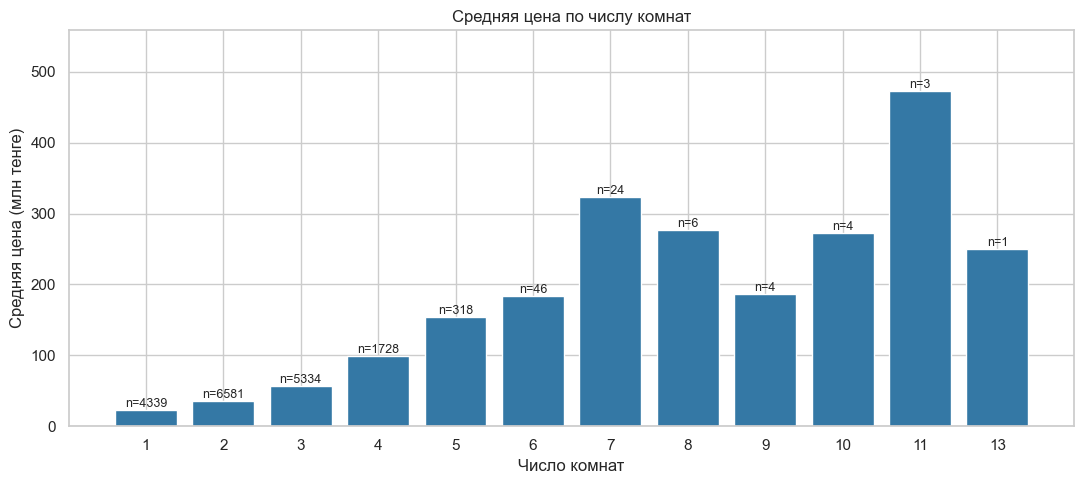

Одна комната: среднее 22.66 млн тенге (n=4339); три комнаты: 57.13 млн (n=5334). Малые группы ненадёжны.

In [10]:
# Столбцы сравнивают средние цены
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(room_summary.index.astype(str), room_summary["mean"] / 1e6, color="#3478a5")
for position, (rooms, row) in enumerate(room_summary.iterrows()):
    ax.text(position, row["mean"] / 1e6, f"n={int(row['count'])}", ha="center", va="bottom", fontsize=9)
ax.set(title="Средняя цена по числу комнат", xlabel="Число комнат",
       ylabel="Средняя цена (млн тенге)")
ax.margins(y=0.18)
plt.tight_layout()
plt.show()
display(Markdown(f"Одна комната: среднее {room_summary.loc[1, 'mean']/1e6:.2f} млн тенге "
    f"(n={room_summary.loc[1, 'count']:.0f}); три комнаты: {room_summary.loc[3, 'mean']/1e6:.2f} млн "
    f"(n={room_summary.loc[3, 'count']:.0f}). Малые группы ненадёжны."))

#### Цена и площадь

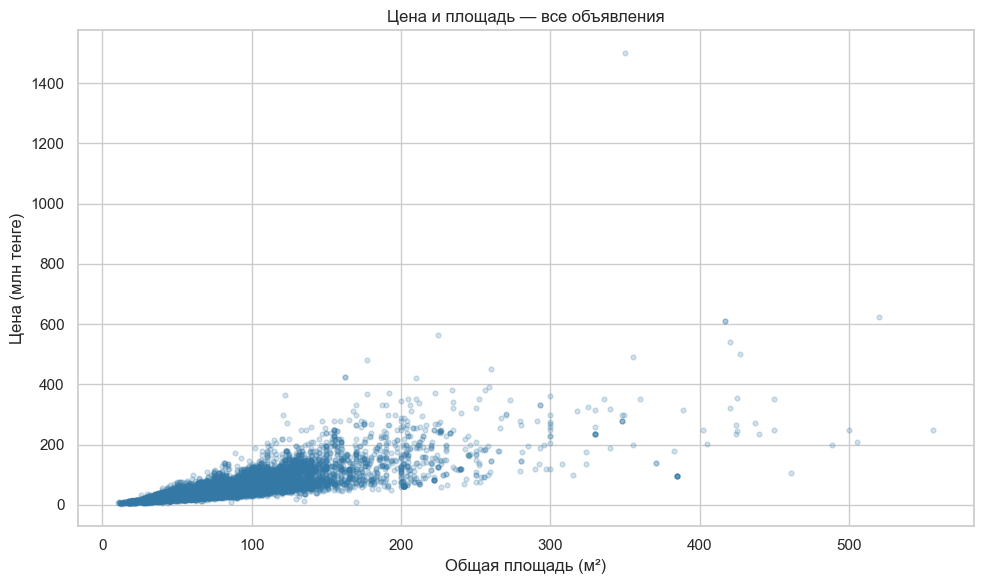

Связь площади с ценой: **r=0.793**. Максимальная цена 1,500 млн тенге растягивает шкалу; выбросы влияют на r.

In [11]:
# Каждая точка — квартира
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(apartments.area, apartments.price / 1e6, s=12, alpha=0.22, color="#3478a5")
ax.set(title="Цена и площадь — все объявления", xlabel="Общая площадь (м²)",
       ylabel="Цена (млн тенге)")
plt.tight_layout()
plt.show()
area_price_r = apartments[["area", "price"]].corr().loc["area", "price"]
display(Markdown(f"Связь площади с ценой: **r={area_price_r:.3f}**. "
    f"Максимальная цена {apartments.price.max()/1e6:,.0f} млн тенге растягивает шкалу; "
    "выбросы влияют на r."))

#### Разброс цен по комнатам

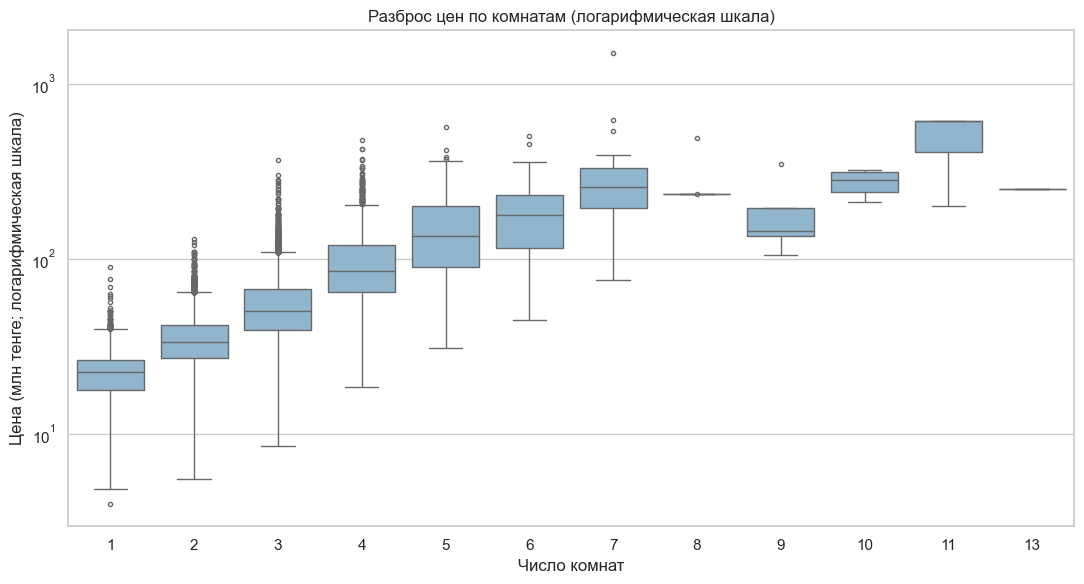

Медиана двухкомнатных — 33.50 млн тенге, четырёхкомнатных — 85.00 млн. Точки за усами — возможные выбросы; единичные группы ненадёжны.

In [12]:
# Boxplot показывает медиану и разброс
fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=apartments.assign(price_million=apartments.price / 1e6), x="rooms",
            y="price_million", ax=ax, color="#86b8d6", flierprops={"markersize": 3})
ax.set_yscale("log")
ax.set(title="Разброс цен по комнатам (логарифмическая шкала)",
       xlabel="Число комнат", ylabel="Цена (млн тенге; логарифмическая шкала)")
plt.tight_layout()
plt.show()
display(Markdown(f"Медиана двухкомнатных — {room_summary.loc[2, 'median']/1e6:.2f} млн тенге, "
    f"четырёхкомнатных — {room_summary.loc[4, 'median']/1e6:.2f} млн. "
    "Точки за усами — возможные выбросы; единичные группы ненадёжны."))

#### Распределение цены за м²

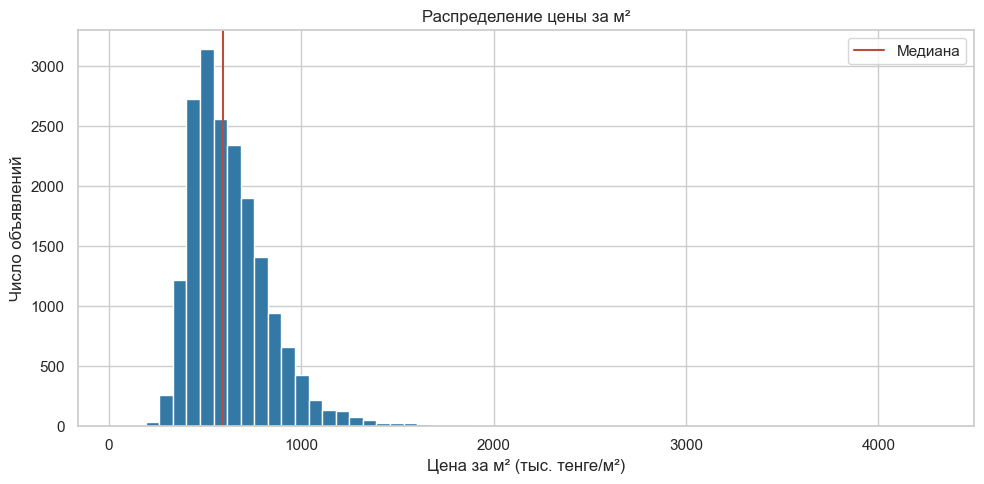

Среднее — 631,323, медиана — 590,909 тенге/м². Асимметрия 1.84: правый хвост дорогих объявлений поднимает среднее.

In [13]:
# Гистограмма показывает частоты
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(apartments.price_per_m2 / 1000, bins=60, color="#3478a5", edgecolor="white")
ax.axvline(apartments.price_per_m2.median() / 1000, color="#bd4b39", label="Медиана")
ax.set(title="Распределение цены за м²", xlabel="Цена за м² (тыс. тенге/м²)",
       ylabel="Число объявлений")
ax.legend()
plt.tight_layout()
plt.show()
display(Markdown(f"Среднее — {apartments.price_per_m2.mean():,.0f}, "
    f"медиана — {apartments.price_per_m2.median():,.0f} тенге/м². "
    f"Асимметрия {apartments.price_per_m2.skew():.2f}: правый хвост дорогих объявлений поднимает среднее."))

#### Матрица корреляций

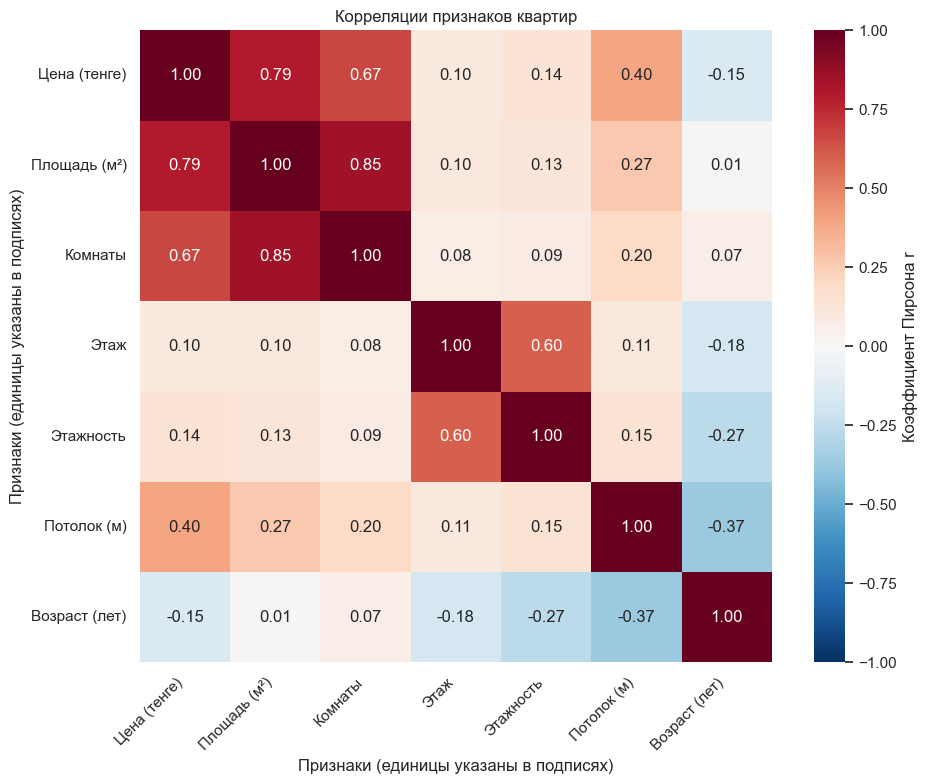

С ценой сильнее всего связаны **area** (r=0.793) и **rooms** (r=0.669). Корреляция не доказывает причину.

In [14]:
# Расчёт и вывод результата.
correlation_columns = ["price", "area", "rooms", "floor", "total_floors", "ceiling_m", "building_age"]
correlation_matrix = apartments[correlation_columns].corr()
plot_labels = ["Цена (тенге)", "Площадь (м²)", "Комнаты", "Этаж", "Этажность", "Потолок (м)", "Возраст (лет)"]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            center=0, square=True, xticklabels=plot_labels, yticklabels=plot_labels,
            cbar_kws={"label": "Коэффициент Пирсона r"}, ax=ax)
ax.set(title="Корреляции признаков квартир", xlabel="Признаки (единицы указаны в подписях)",
       ylabel="Признаки (единицы указаны в подписях)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
price_correlations = correlation_matrix["price"].drop("price")
ranked_correlations = price_correlations.loc[price_correlations.abs().sort_values(ascending=False).index]
display(Markdown(f"С ценой сильнее всего связаны **{ranked_correlations.index[0]}** "
    f"(r={ranked_correlations.iloc[0]:.3f}) и **{ranked_correlations.index[1]}** "
    f"(r={ranked_correlations.iloc[1]:.3f}). Корреляция не доказывает причину."))

### 4.4. Корреляция и выводы

In [15]:
# Считаем число полных пар
pair_counts = apartments[correlation_columns].notna().astype(int)
pair_counts = pair_counts.T.dot(pair_counts)
correlation_report = ranked_correlations.rename("Pearson_r").to_frame()
correlation_report["pairs_with_price"] = pair_counts.loc[correlation_report.index, "price"]
display(correlation_report)
positive_correlations = price_correlations[price_correlations > 0].sort_values(ascending=False)
negative_correlations = price_correlations[price_correlations < 0].sort_values()
if not positive_correlations.empty:
    print(f"Самая сильная положительная связь: {positive_correlations.index[0]}, r={positive_correlations.iloc[0]:.4f}")
else:
    print("Положительной связи нет.")
if not negative_correlations.empty:
    print(f"Самая сильная отрицательная связь: {negative_correlations.index[0]}, r={negative_correlations.iloc[0]:.4f}")
else:
    print("Отрицательной связи нет.")
display(Markdown(f"""1. **Комнаты:** средняя цена однокомнатных — {room_summary.loc[1, 'mean']/1e6:.2f} млн тенге (n={room_summary.loc[1, 'count']:.0f}), трёхкомнатных — {room_summary.loc[3, 'mean']/1e6:.2f} млн (n={room_summary.loc[3, 'count']:.0f}).
2. **Районы:** максимальная средняя у {highest_district} — {district_summary.loc[highest_district, 'mean']/1e6:.2f} млн (n={district_summary.loc[highest_district, 'count']:.0f}), минимальная у {lowest_district} — {district_summary.loc[lowest_district, 'mean']/1e6:.2f} млн (n={district_summary.loc[lowest_district, 'count']:.0f}). Состав групп различается.
3. **Scatter:** площадь и цена положительно связаны, r={area_price_r:.3f}; крайние точки сохранены.
4. **Гистограмма:** среднее {apartments.price_per_m2.mean():,.0f} выше медианы {apartments.price_per_m2.median():,.0f} тенге/м² — есть правый хвост.
5. **Корреляция:** самые сильные связи — {ranked_correlations.index[0]} ({ranked_correlations.iloc[0]:.3f}) и {ranked_correlations.index[1]} ({ranked_correlations.iloc[1]:.3f}). Это не причина.
6. **Качество:** неизвестный этаж — {df.floor_category.eq('unknown').sum():,}, район — {df.district.eq('Unknown').sum():,}; будущий год постройки — {df.future_completion.sum():,}. Это объявления, не сделки."""))

,Pearson_r,pairs_with_price
area,0.79,18388
rooms,0.67,18388
ceiling_m,0.40,18388
building_age,-0.15,18351
total_floors,0.14,17417
floor,0.10,17417


Самая сильная положительная связь: area, r=0.7934
Самая сильная отрицательная связь: building_age, r=-0.1476


1. **Комнаты:** средняя цена однокомнатных — 22.66 млн тенге (n=4339), трёхкомнатных — 57.13 млн (n=5334).
2. **Районы:** максимальная средняя у Есильский р-н — 64.66 млн (n=5121), минимальная у Сарыарка р-н — 30.63 млн (n=2104). Состав групп различается.
3. **Scatter:** площадь и цена положительно связаны, r=0.793; крайние точки сохранены.
4. **Гистограмма:** среднее 631,323 выше медианы 590,909 тенге/м² — есть правый хвост.
5. **Корреляция:** самые сильные связи — area (0.793) и rooms (0.669). Это не причина.
6. **Качество:** неизвестный этаж — 971, район — 778; будущий год постройки — 37. Это объявления, не сделки.